block 1 importlar

In [5]:
import torch
import torch.nn as nn
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2
import os
import math
from tqdm import tqdm

block 2 ayarlar

In [ ]:
CONFIG = {
    # Test etmek istediğin herhangi bir _rgb_nir.tif dosyası
    "TEST_IMAGE_PATH": "yeniiii/burdur_12_2015_merged.tif",
    "MODEL_PATH": "gol_bulucu_unet_sentinel.pth",  # Eğittiğimiz model dosyası

    "IMG_HEIGHT": 256,
    "IMG_WIDTH": 256,
    "DEVICE": "cuda" if torch.cuda.is_available() else "cpu"
}

block 3 unet clası

In [7]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, 1, 1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.conv(x)

class UNET(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, features=[64, 128, 256, 512]):
        super().__init__()
        self.ups = nn.ModuleList()
        self.downs = nn.ModuleList()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        for feature in features:
            self.downs.append(DoubleConv(in_channels, feature))
            in_channels = feature

        for feature in reversed(features):
            self.ups.append(nn.ConvTranspose2d(feature*2, feature, kernel_size=2, stride=2))
            self.ups.append(DoubleConv(feature*2, feature))
        self.bottleneck = DoubleConv(features[-1], features[-1]*2)
        self.final_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)

    def forward(self, x):
        skip_connections = []
        for down in self.downs:
            x = down(x)
            skip_connections.append(x)
            x = self.pool(x)
        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1]
        for idx in range(0, len(self.ups), 2):
            x = self.ups[idx](x)
            skip_connection = skip_connections[idx//2]
            if x.shape != skip_connection.shape:
                x = torch.nn.functional.interpolate(x, size=skip_connection.shape[2:])
            concat_skip = torch.cat((skip_connection, x), dim=1)
            x = self.ups[idx+1](concat_skip)
        return self.final_conv(x)

block 4 çıktı

Model yükleniyor: gol_bulucu_unet_sentinel.pth
Görüntü okunuyor (Resize YAPILMADAN)...
Orijinal Boyutlar: 849x837
Toplam 16 parça işlenecek...


Satırlar İşleniyor: 100%|██████████| 4/4 [00:00<00:00, 23.38it/s]


Görselleştirme yapılıyor...


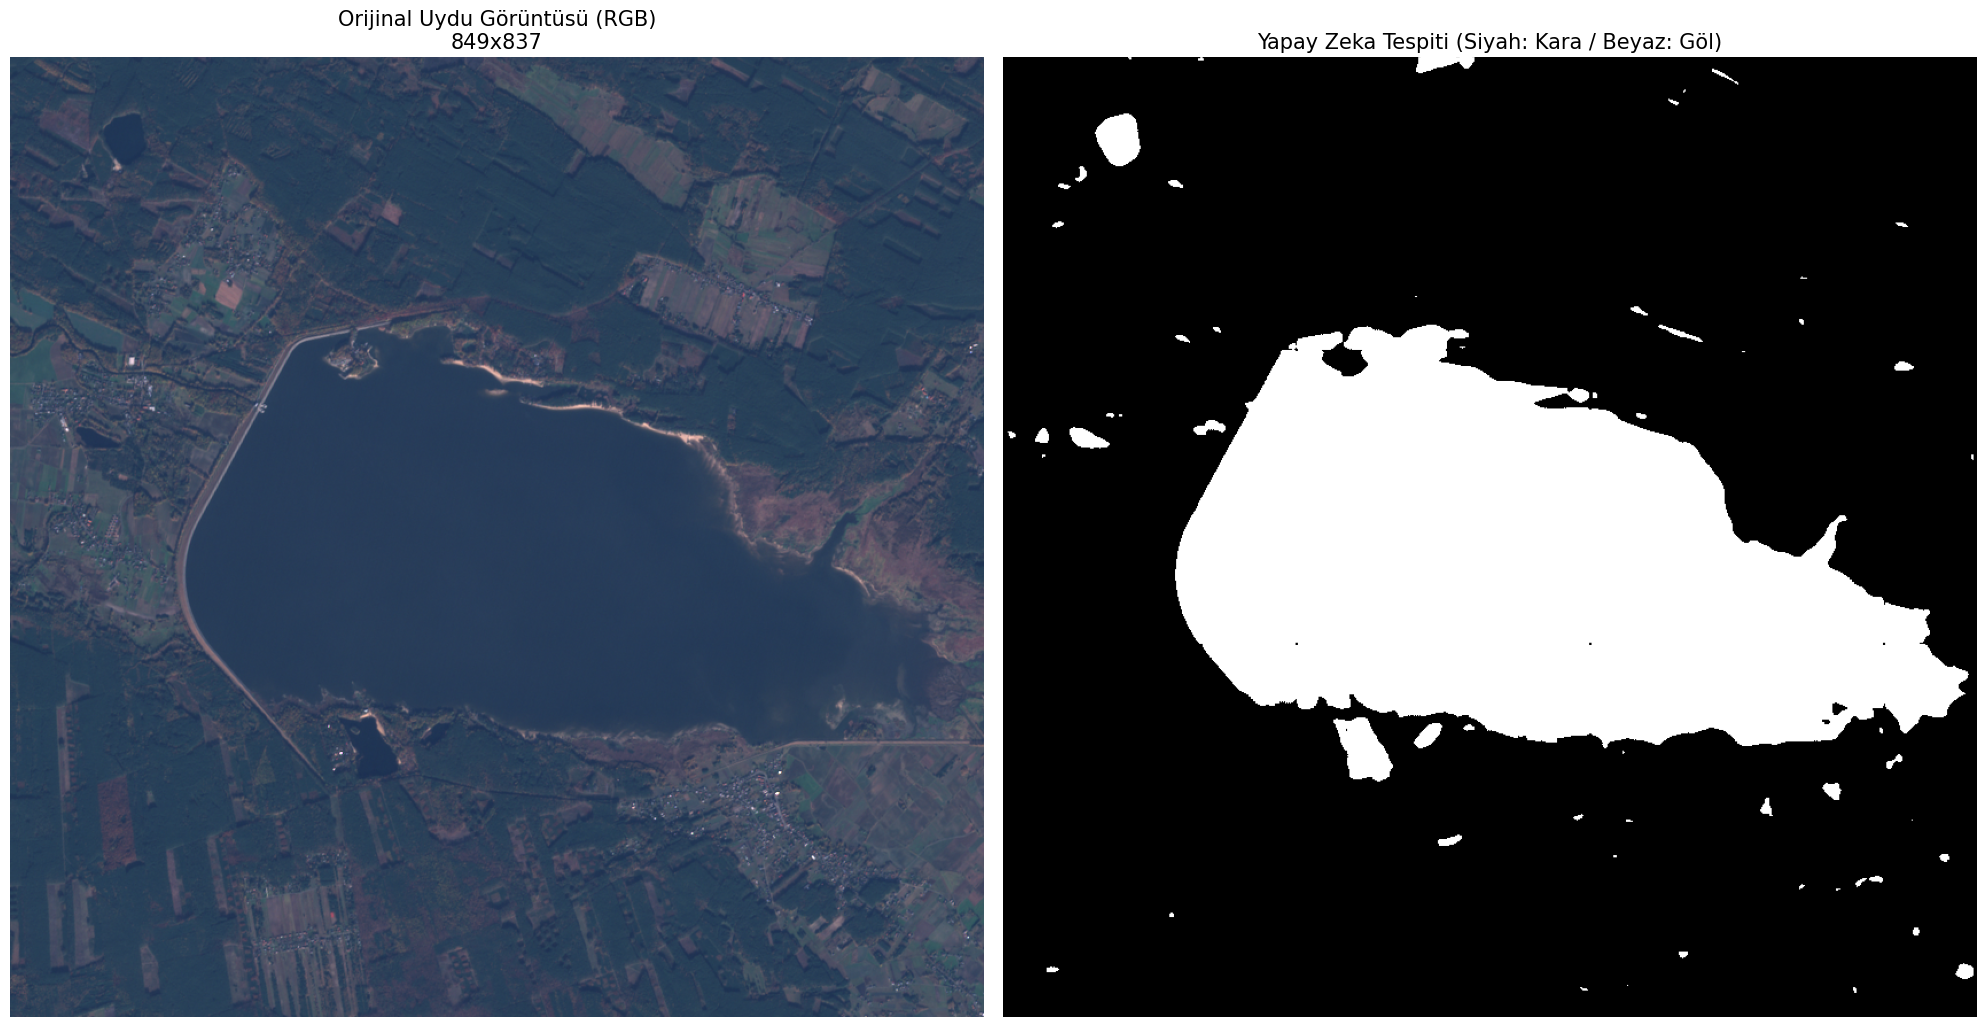

✅ İşlem tamamlandı! Karşılaştırma ekranda.


In [8]:
import math
from tqdm import tqdm
import cv2

def predict_full_image():
    print(f"Model yükleniyor: {CONFIG['MODEL_PATH']}")
    
    # 1. Modeli Hazırla
    model = UNET(in_channels=4, out_channels=1).to(CONFIG["DEVICE"])
    try:
        model.load_state_dict(torch.load(CONFIG["MODEL_PATH"], map_location=CONFIG["DEVICE"]))
    except FileNotFoundError:
        print("HATA: Model dosyası bulunamadı!")
        return
    model.eval()

    if not os.path.exists(CONFIG["TEST_IMAGE_PATH"]):
        print("HATA: Resim bulunamadı.")
        return

    print("Görüntü okunuyor...")
    with rasterio.open(CONFIG["TEST_IMAGE_PATH"]) as src:
        # Tüm resmi orijinal boyutunda okuyoruz (H, W, 4)
        full_image = src.read([1, 2, 3, 4]).transpose(1, 2, 0)
        original_height, original_width = full_image.shape[:2]
        
    print(f"Orijinal Boyutlar: {original_width}x{original_height}")

    # 2. Normalizasyon
    full_image = full_image.astype(np.float32)
    display_image = full_image[:, :, :3].copy()
    
    if full_image.max() > 255.0:
        full_image = full_image / 10000.0
        display_image = display_image / 10000.0
    else:
        full_image = full_image / 255.0
        display_image = display_image / 255.0
    
    display_image = np.clip(display_image * 3.5, 0, 1)

    # 3. Resize ve Tek Parça Tahmin
    target_size = (256, 256)
    
    # Resmi 256x256'ya küçült
    resized_img = cv2.resize(full_image, target_size, interpolation=cv2.INTER_LINEAR)
    
    # Tensöre çevir
    tensor_img = torch.from_numpy(resized_img).permute(2, 0, 1).unsqueeze(0).float().to(CONFIG["DEVICE"])
    
    print("Tek parça tahmin yapılıyor...")
    with torch.no_grad():
        prediction = torch.sigmoid(model(tensor_img))
        prediction = prediction.squeeze().cpu().numpy()
        
    # Maskeyi orijinal boyuta geri büyüt
    full_mask = cv2.resize(prediction, (original_width, original_height), interpolation=cv2.INTER_LINEAR)

    # 4. Sonuçları Yan Yana Çizdir
    print("Görselleştirme yapılıyor...")
    binary_mask = (full_mask > 0.5).astype(np.uint8)

    plt.figure(figsize=(20, 10))

    # Sol Taraf: Orijinal RGB Görüntü
    plt.subplot(1, 2, 1)
    plt.title(f"Orijinal Uydu Görüntüsü (RGB)\n{original_width}x{original_height}", fontsize=15)
    plt.imshow(display_image)
    plt.axis("off")

    # Sağ Taraf: Yapay Zeka Tespiti
    plt.subplot(1, 2, 2)
    plt.title("Yapay Zeka Tespiti (Siyah: Kara / Beyaz: Göl)", fontsize=15)
    plt.imshow(binary_mask, cmap="gray")
    plt.axis("off")

    plt.tight_layout()
    plt.show()
    
    print("✅ İşlem tamamlandı! Tek parça işleme (resize) kullanıldı.")

if __name__ == "__main__":
    predict_full_image()